# COU 07506 — Week 2: Lab 1A, Sampling, Aliasing and Quantization

**Student:** Zaid Yaseer Yussuf &nbsp;|&nbsp; **Registration number:** 240242479517 &nbsp;|&nbsp;
**Class:** BEng24COE &nbsp;|&nbsp; **Date:** 26 November 2026 &nbsp;|&nbsp;
**Submission:** Individual laboratory work.

## Pre-lab preparation

**Reading.** Handout §1.2, Listings 1.1–1.2 and Example 1.1.

**(a)** A 7 kHz tone sampled at 10 kHz appears at |7 − 10| = **3 kHz**.

**(b)** For an 8-bit quantiser with range ±1 V: Δ = 2/2⁸ = 2/256 =
**7.8125 mV**, and the theoretical SQNR = 6.02 × 8 + 1.76 = **49.9 dB**.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
FIGDIR = ROOT / "report" / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)
DATA = ROOT / "data"
REPORT = ROOT / "report"
REPORT.mkdir(parents=True, exist_ok=True)
print("Repository root:", ROOT)

Repository root: C:\Users\zayee\Documents\Default Project\COU07506-labs


In [2]:
# Functions used in this notebook

def alias_freq(f0, fs):
    """Return (|F - k fs|, k) with k = round(F/fs)."""
    k = round(f0 / fs)
    return abs(f0 - k * fs), k

def quantize(x, bits, full_scale=1.0):
    """Uniform mid-tread quantiser on [-full_scale, full_scale - delta]."""
    delta = 2 * full_scale / 2**bits
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

def sqnr_db(x, xq):
    return float(10 * np.log10(np.sum(x**2) / np.sum((x - xq)**2)))

def chirp_signal(fs=44100, T=3):
    t = np.arange(0, T, 1 / fs)
    return fs, 0.5 * signal.chirp(t, 200, T, 15000)

def speech_like(fs=16000, T=4.7, seed=3):
    """Synthetic speech-like signal: voiced bursts plus noise (fixed seed)."""
    rng = np.random.default_rng(seed)
    t = np.arange(0, T, 1 / fs)
    env = np.zeros_like(t)
    for centre, width, amp in [(0.9, 0.18, 0.7), (1.5, 0.15, 0.5),
                               (2.3, 0.22, 1.0), (3.0, 0.20, 0.8),
                               (3.8, 0.25, 0.45)]:
        env += amp * np.exp(-0.5 * ((t - centre) / width) ** 2)
    f0 = 110 + 25 * np.sin(2 * np.pi * 0.4 * t)
    phase = 2 * np.pi * np.cumsum(f0) / fs
    voiced = sum(np.sin(k * phase) / k**0.8 for k in range(1, 30))
    b, a = signal.butter(2, [300, 2500], btype="band", fs=fs)
    voiced = signal.lfilter(b, a, voiced)
    b2, a2 = signal.butter(2, 1500, btype="high", fs=fs)
    noise = signal.lfilter(b2, a2, rng.standard_normal(len(t)))
    x = env * voiced + 0.02 * noise + 0.1 * env * noise
    return fs, x / np.max(np.abs(x))

## Task 2.1 — Aliasing of a sinusoid

A 7 Hz cosine is drawn on a dense grid (the "analog" signal) together with its
samples and the predicted alias for fs = 10, 12, 14 and 20 Hz.

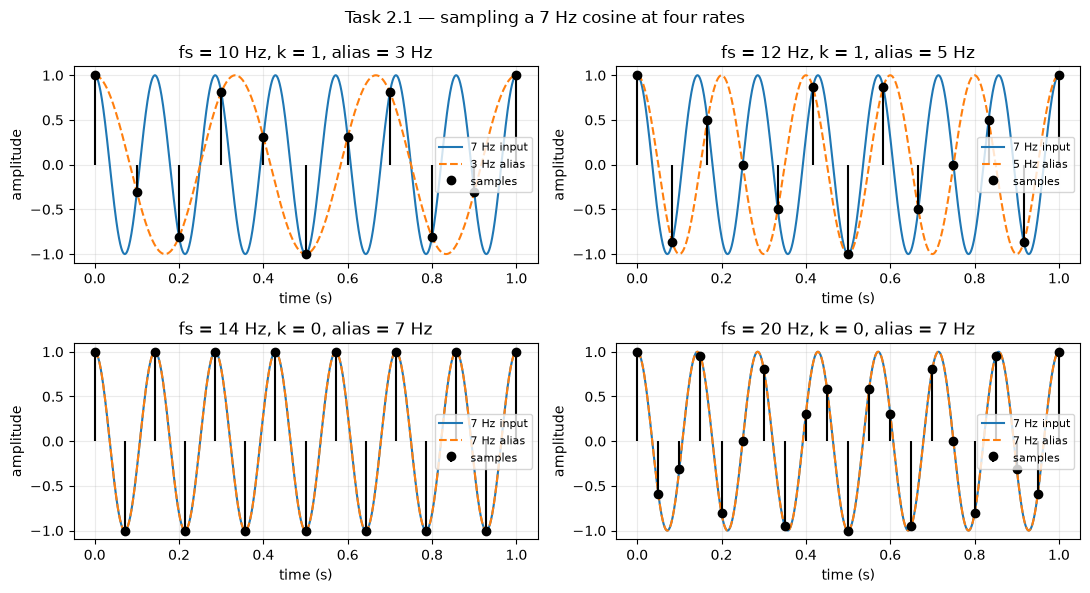

,fs_Hz,k,abs_F_minus_kfs_Hz,comment
0,10,1,3.0,aliased
1,12,1,5.0,aliased
2,14,0,7.0,no alias / Nyquist limit
3,20,0,7.0,no alias / Nyquist limit


In [3]:
f0 = 7.0
t_dense = np.linspace(0, 1, 2000)
alias_rows = []
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, fs_now in zip(axes.ravel(), [10, 12, 14, 20]):
    fa, k = alias_freq(f0, fs_now)
    n = np.arange(0, int(fs_now) + 1)
    tn = n / fs_now
    ax.plot(t_dense, np.cos(2*np.pi*f0*t_dense), label="7 Hz input")
    ax.plot(t_dense, np.cos(2*np.pi*fa*t_dense), "--", label=f"{fa:g} Hz alias")
    ax.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko",
            basefmt=" ", label="samples")
    ax.set_title(f"fs = {fs_now} Hz, k = {k}, alias = {fa:g} Hz")
    ax.set_xlabel("time (s)")
    ax.set_ylabel("amplitude")
    ax.legend(fontsize=8)
    alias_rows.append({"fs_Hz": fs_now, "k": k, "abs_F_minus_kfs_Hz": fa,
                       "comment": ("aliased" if fa != f0 else "no alias / Nyquist limit")})
fig.suptitle("Task 2.1 — sampling a 7 Hz cosine at four rates")
fig.tight_layout()
fig.savefig(FIGDIR / "week02_task2_1.png", dpi=160, bbox_inches="tight")
plt.show()
display(pd.DataFrame(alias_rows))

## Task 2.2 — Aliasing in a decimated signal

The manual's 3 s chirp (200 Hz → 15 kHz at 44.1 kHz) is used so the result is
reproducible. Each decimation by k is done once by keeping every k-th sample and
once with `signal.decimate`, which low-pass filters before discarding samples.

k = 2: new fs = 22050 Hz, new Nyquist = 11025 Hz
k = 4: new fs = 11025 Hz, new Nyquist = 5512.5 Hz
k = 8: new fs = 5512.5 Hz, new Nyquist = 2756.25 Hz


,k,new_fs_Hz,rms_naive,rms_decimate,rms_predicted_filtered
0,2,22050.0,0.353386,0.296627,0.302370
1,4,11025.0,0.353146,0.207711,0.211823
2,8,5512.5,0.352165,0.143721,0.146935


C:\Users\zayee\AppData\Local\Temp\ipykernel_26860\847155317.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


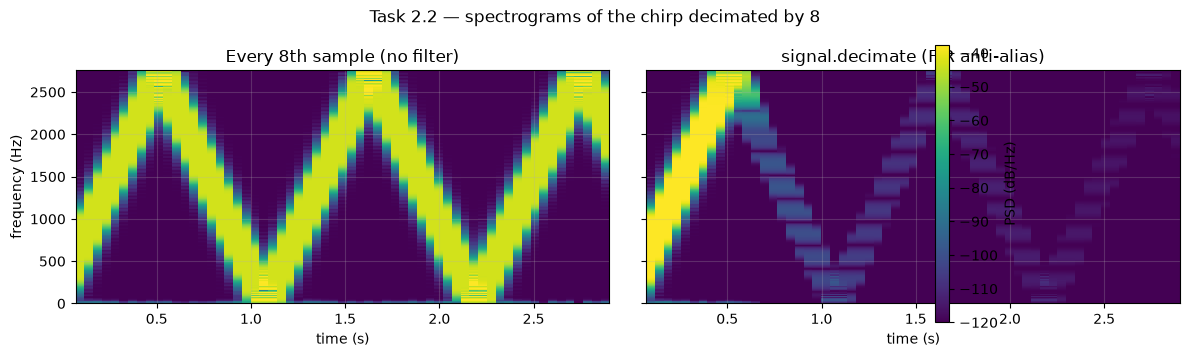

In [4]:
fs_chirp, x_chirp = chirp_signal()
x_chirp_rms = float(np.sqrt(np.mean(x_chirp**2)))
decim_rows = []
for k in [2, 4, 8]:
    naive = x_chirp[::k]
    proper = signal.decimate(x_chirp, k, ftype="fir")
    new_fs = fs_chirp / k
    nyquist = new_fs / 2
    frac = np.clip((nyquist - 200) / (15000 - 200), 0.0, 1.0)
    predicted = x_chirp_rms * np.sqrt(frac)
    decim_rows.append({"k": k, "new_fs_Hz": new_fs,
                       "rms_naive": float(np.sqrt(np.mean(naive**2))),
                       "rms_decimate": float(np.sqrt(np.mean(proper**2))),
                       "rms_predicted_filtered": float(predicted)})
    print(f"k = {k}: new fs = {new_fs:g} Hz, new Nyquist = {nyquist:g} Hz")
display(pd.DataFrame(decim_rows))

naive8 = x_chirp[::8]
proper8 = signal.decimate(x_chirp, 8, ftype="fir")
fs8 = fs_chirp / 8
f_n, t_n, Z_n = signal.spectrogram(naive8, fs=fs8, nperseg=1024, noverlap=768)
f_p, t_p, Z_p = signal.spectrogram(proper8, fs=fs8, nperseg=1024, noverlap=768)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, tt, ff, ZZ, title in [
    (axes[0], t_n, f_n, Z_n, "Every 8th sample (no filter)"),
    (axes[1], t_p, f_p, Z_p, "signal.decimate (FIR anti-alias)"),
]:
    im = ax.pcolormesh(tt, ff, 10*np.log10(ZZ + 1e-12), shading="auto", cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("time (s)")
    ax.set_ylim(0, fs8 / 2)
axes[0].set_ylabel("frequency (Hz)")
fig.colorbar(im, ax=axes, label="PSD (dB/Hz)")
fig.suptitle("Task 2.2 — spectrograms of the chirp decimated by 8")
fig.tight_layout()
fig.savefig(FIGDIR / "week02_task2_2_spec.png", dpi=160, bbox_inches="tight")
plt.show()

# Listening check (uncomment in a notebook):
# display(Audio(naive8, rate=int(fs8)))
# display(Audio(proper8, rate=int(fs8)))

**Listening observation.** The unfiltered version sweeps up to the new Nyquist
frequency (2756 Hz) and then folds back, producing a repeated zig-zag and an
unnatural "descending again" tone. The filtered version contains only the part of
the sweep below 2756 Hz followed by near-silence.

## Task 2.3 — A uniform quantiser

A 300 Hz sinusoid of amplitude 0.99 sampled at 8 kHz (80 samples, three cycles)
is quantised with B = 3 bits, so Δ = 2/8 = 0.25.

delta = 0.25, +/-delta/2 = +/-0.125, max |error| = 0.2400


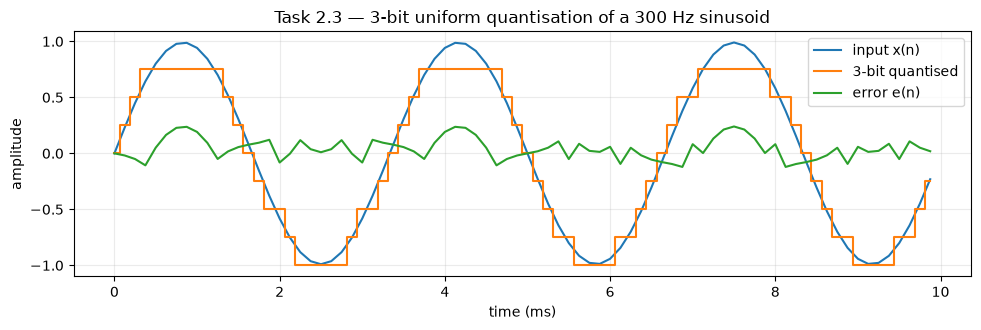

In [5]:
fs_q = 8000
t_q = np.arange(0, 0.01, 1 / fs_q)
x_sine = 0.99 * np.sin(2 * np.pi * 300 * t_q)
delta3 = 2 / 2**3
xq3 = quantize(x_sine, 3)
max_err3 = float(np.max(np.abs(x_sine - xq3)))
print(f"delta = {delta3}, +/-delta/2 = +/-{delta3/2}, max |error| = {max_err3:.4f}")

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(t_q * 1e3, x_sine, label="input x(n)")
ax.step(t_q * 1e3, xq3, where="mid", label="3-bit quantised")
ax.plot(t_q * 1e3, x_sine - xq3, label="error e(n)")
ax.set_title("Task 2.3 — 3-bit uniform quantisation of a 300 Hz sinusoid")
ax.set_xlabel("time (ms)")
ax.set_ylabel("amplitude")
ax.legend()
fig.tight_layout()
fig.savefig(FIGDIR / "week02_task2_3.png", dpi=160, bbox_inches="tight")
plt.show()

The error remains inside ±Δ/2 = ±0.125 except at the positive peaks, where 0.99
would round to 1.0 but the quantiser clips to 1 − Δ = 0.75; the largest error is
therefore about 0.24.

## Task 2.4 — Verify the 6 dB-per-bit rule

Measure SQNR = 10 log₁₀(Σx²/Σe²) for B = 2, 4, …, 16 and compare with
6.02B + 1.76 dB.

,B,measured_dB,theory_dB,difference_dB
0,2,9.60,13.80,-4.20
1,4,23.58,25.84,-2.26
2,6,36.81,37.88,-1.07
3,8,48.93,49.92,-0.99
4,10,62.81,61.96,0.85
5,12,72.84,74.00,-1.16
6,14,88.13,86.04,2.09
7,16,98.91,98.08,0.83


Fitted slope for B >= 4: 6.30 dB/bit (theory 6.02 dB/bit)


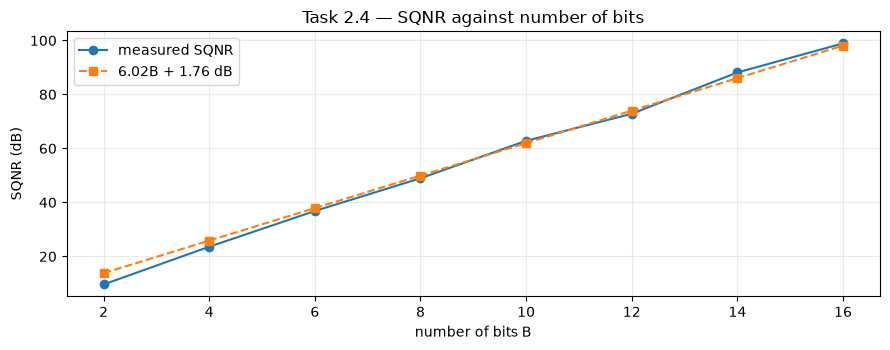

In [6]:
bits = np.arange(2, 17, 2)
measured = [sqnr_db(x_sine, quantize(x_sine, int(B))) for B in bits]
theory = (6.02 * bits + 1.76).tolist()
mask = bits >= 4
slope = float(np.polyfit(bits[mask], np.array(measured)[mask], 1)[0])
sqnr_table = [{"B": int(B), "measured_dB": round(m, 2),
               "theory_dB": round(t, 2), "difference_dB": round(m - t, 2)}
              for B, m, t in zip(bits, measured, theory)]
display(pd.DataFrame(sqnr_table))
print(f"Fitted slope for B >= 4: {slope:.2f} dB/bit (theory 6.02 dB/bit)")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(bits, measured, "o-", label="measured SQNR")
ax.plot(bits, theory, "s--", label="6.02B + 1.76 dB")
ax.set_title("Task 2.4 — SQNR against number of bits")
ax.set_xlabel("number of bits B")
ax.set_ylabel("SQNR (dB)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGDIR / "week02_task2_4.png", dpi=160, bbox_inches="tight")
plt.show()

## Task 2.5 — Quantising speech

The speech-like signal (16 kHz, 4.7 s, seed 3) is quantised to 4, 8 and 12 bits;
a full-scale sine is quantised in the same way for comparison.

,B,speech_SQNR_dB,sine_SQNR_dB,theory_dB,gap_dB
0,4,10.73,23.27,25.84,12.54
1,8,30.55,50.10,49.92,19.55
2,12,54.64,73.84,74.00,19.19


Crest factor = 13.16
Crest-factor penalty = 19.4 dB


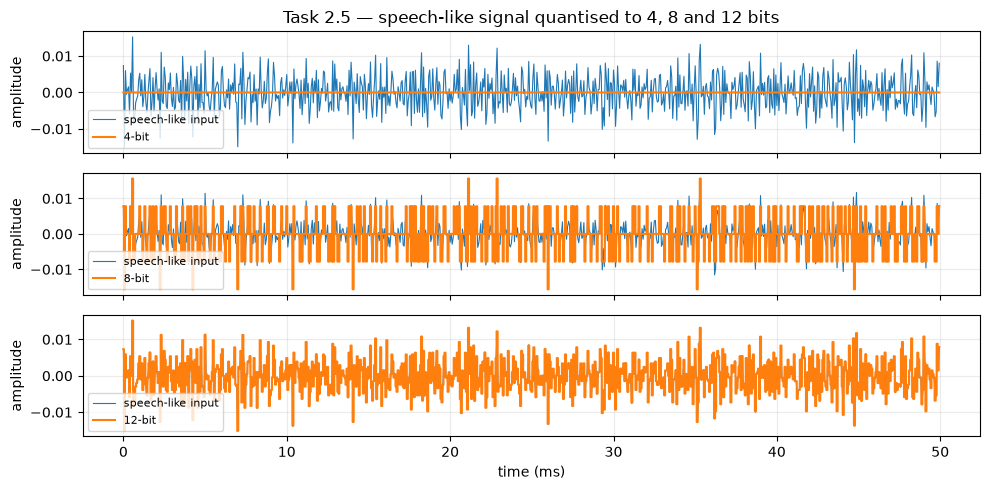

In [7]:
fs_sp, x_sp = speech_like()
crest = float(np.max(np.abs(x_sp)) / np.sqrt(np.mean(x_sp**2)))
sine_full = 0.999 * np.sin(2 * np.pi * 440 * np.arange(len(x_sp)) / fs_sp)
speech_rows = []
for B in [4, 8, 12]:
    qs = sqnr_db(x_sp, quantize(x_sp, B))
    qn = sqnr_db(sine_full, quantize(sine_full, B))
    speech_rows.append({"B": B, "speech_SQNR_dB": round(qs, 2),
                        "sine_SQNR_dB": round(qn, 2),
                        "theory_dB": round(6.02*B + 1.76, 2),
                        "gap_dB": round(qn - qs, 2)})
display(pd.DataFrame(speech_rows))
crest_penalty = 20 * np.log10(crest / np.sqrt(2))
print(f"Crest factor = {crest:.2f}")
print(f"Crest-factor penalty = {crest_penalty:.1f} dB")

fig, axes = plt.subplots(3, 1, figsize=(10, 5), sharex=True)
t_sp = np.arange(800) / fs_sp
for ax, B in zip(axes, [4, 8, 12]):
    ax.plot(t_sp * 1e3, x_sp[:800], label="speech-like input", lw=0.8)
    ax.step(t_sp * 1e3, quantize(x_sp, B)[:800], where="mid", label=f"{B}-bit")
    ax.set_ylabel("amplitude")
    ax.legend(fontsize=8)
axes[0].set_title("Task 2.5 — speech-like signal quantised to 4, 8 and 12 bits")
axes[-1].set_xlabel("time (ms)")
fig.tight_layout()
fig.savefig(FIGDIR / "week02_task2_5.png", dpi=160, bbox_inches="tight")
plt.show()

**Listening observation.** At 4 bits the speech is gritty and the quantisation
noise is obvious in pauses. At 8 bits the noise is quiet but still audible; at
12 bits it is essentially inaudible. The measured SQNR is about 20 dB below the
full-scale sine because the crest factor is large: the step Δ is set by the peak
while the average power is much lower.

## Analysis questions

1. **Frequency-axis sketch.** Sampling at 10 Hz repeats the spectrum at
   ±k·10 Hz. The copy of +7 Hz at 7 − 10 = −3 Hz and the copy of −7 Hz at
   −7 + 10 = +3 Hz both fall inside the baseband, so the 7 Hz tone is seen as 3 Hz.
2. **Aliasing cannot be removed afterwards.** After sampling, a genuine 3 Hz
   component and an aliased 7 Hz component give identical samples. The
   information that distinguishes them has been lost, so only an anti-alias
   filter **before** sampling/decimation can prevent it.
3. **Change per bit.** Adding one bit halves Δ, so the noise power Δ²/12 falls by
   a factor of 4 = 10 log₁₀4 ≈ 6.02 dB. The measured slope (printed above) agrees.
4. **Temperature sensor.** Range 0–100 °C with 0.01 °C resolution needs
   100/0.01 = 10 000 levels, so B = ceil(log₂10 000) = 14 bits. The signal changes
   by at most 0.1 °C/s, so fs = 1 Hz is adequate; a higher rate such as 10 Hz with
   averaging could reduce noise but is not required.

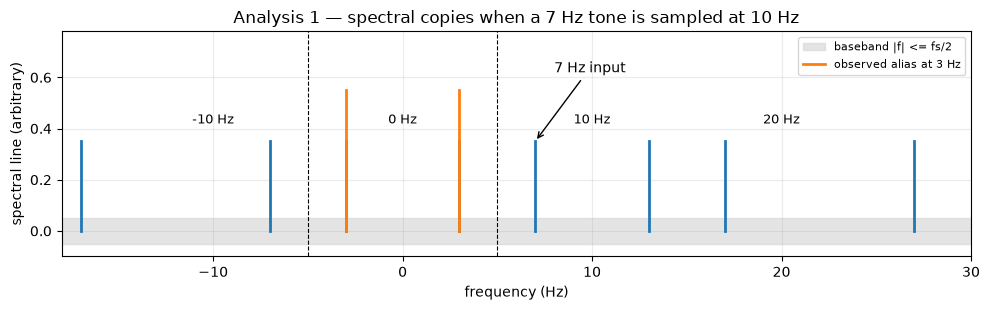

In [8]:
# Frequency-axis sketch for analysis question 1
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.axhspan(-0.05, 0.05, color="lightgrey", alpha=0.6, label="baseband |f| <= fs/2")
for m in [-1, 0, 1, 2]:
    centre = m * 10
    for sign in [-1, 1]:
        ax.plot([centre + sign*7, centre + sign*7], [0, 0.35], color="C0", lw=2)
    ax.text(centre, 0.42, f"{centre} Hz", ha="center", fontsize=9)
ax.plot([3, 3], [0, 0.55], color="C1", lw=2, label="observed alias at 3 Hz")
ax.plot([-3, -3], [0, 0.55], color="C1", lw=2)
ax.axvline(-5, color="k", ls="--", lw=0.8)
ax.axvline(5, color="k", ls="--", lw=0.8)
ax.annotate("7 Hz input", xy=(7, 0.35), xytext=(8, 0.62),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_xlim(-18, 30)
ax.set_ylim(-0.1, 0.78)
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("spectral line (arbitrary)")
ax.set_title("Analysis 1 — spectral copies when a 7 Hz tone is sampled at 10 Hz")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "week02_analysis_alias.png", dpi=160, bbox_inches="tight")
plt.show()

In [9]:
results_week02 = {
    "week": 2,
    "alias": alias_rows,
    "decimation": decim_rows,
    "quant3": {"delta": delta3, "max_error": round(max_err3, 4)},
    "sqnr_bits": {"bits": [int(b) for b in bits],
                  "measured": [round(v, 2) for v in measured],
                  "theory": [round(v, 2) for v in theory],
                  "slope_dB_per_bit": round(slope, 2)},
    "speech": {"crest_factor": round(crest, 2),
               "crest_penalty_dB": round(float(crest_penalty), 1),
               "rows": speech_rows},
}
(REPORT / "results_week02.json").write_text(json.dumps(results_week02, indent=2))
print(json.dumps(results_week02, indent=2))

{
  "week": 2,
  "alias": [
    {
      "fs_Hz": 10,
      "k": 1,
      "abs_F_minus_kfs_Hz": 3.0,
      "comment": "aliased"
    },
    {
      "fs_Hz": 12,
      "k": 1,
      "abs_F_minus_kfs_Hz": 5.0,
      "comment": "aliased"
    },
    {
      "fs_Hz": 14,
      "k": 0,
      "abs_F_minus_kfs_Hz": 7.0,
      "comment": "no alias / Nyquist limit"
    },
    {
      "fs_Hz": 20,
      "k": 0,
      "abs_F_minus_kfs_Hz": 7.0,
      "comment": "no alias / Nyquist limit"
    }
  ],
  "decimation": [
    {
      "k": 2,
      "new_fs_Hz": 22050.0,
      "rms_naive": 0.3533859011159602,
      "rms_decimate": 0.296626552635607,
      "rms_predicted_filtered": 0.30236977975156115
    },
    {
      "k": 4,
      "new_fs_Hz": 11025.0,
      "rms_naive": 0.3531456672281576,
      "rms_decimate": 0.20771075419906176,
      "rms_predicted_filtered": 0.2118233843584327
    },
    {
      "k": 8,
      "new_fs_Hz": 5512.5,
      "rms_naive": 0.3521648708345139,
      "rms_decimate": 0.1437214

## AI-use statement

**Tool:** OpenCode (model Big Pickle). **Used for:** drafting the Python code and
written answers in this notebook. **Verification:** the notebook was restarted
and run from top to bottom; alias frequencies were checked against |F − kfₛ|, the
decimated RMS against the analytic prediction, the measured SQNR against
6.02B + 1.76 dB, and the speech penalty against the crest-factor formula. I can
explain every line of code.